In [124]:
import os
import scanpy as sc
import anndata as ad
import pandas as pd
from adpbulk import ADPBulk
import numpy as np
import squidpy as sq
from scipy.sparse import csr_matrix
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore")

In [125]:
in_dir = "../../results/02_10x_visium/01_filter_data"
anno_dir = "../../results/09_analysis_podocyte_niche/02_identify_podocyte_niche/update"
out_dir = "../../results/09_analysis_podocyte_niche/05_create_bulk"
os.makedirs(out_dir, exist_ok=True)

In [126]:
sample_list = ['15837', '15852', '16512', '21022', '8262', 
               'B23-03794-5', 'B23-05785-7-1', 'B23-05785-7-2', 
               'X1842', 'X1845', 'X1899', 'X1912']

In [127]:
df_count_list, df_obs = [], []
for sample in sample_list:
    print(f"Processing sample {sample}...")
    adata = sc.read_h5ad(f"{in_dir}/{sample}.h5ad")

    # add annotation
    df_anno = pd.read_csv(f"{anno_dir}/{sample}_1.csv", index_col=0)
    adata.obs = adata.obs.merge(df_anno, 
                                left_index=True, 
                                right_index=True)

    # visualize annotation
    fig, ax = plt.subplots(figsize=(6, 6))
    sq.pl.spatial_scatter(adata, color="annotation", 
                          ax=ax)
    plt.savefig(f"{out_dir}/{sample}_annotation.png", dpi=300)
    plt.close(fig)

    df_count_list.append(adata.to_df())
    df_obs.append(adata.obs)

Processing sample 15837...
Processing sample 15852...
Processing sample 16512...
Processing sample 21022...
Processing sample 8262...
Processing sample B23-03794-5...
Processing sample B23-05785-7-1...
Processing sample B23-05785-7-2...
Processing sample X1842...
Processing sample X1845...
Processing sample X1899...
Processing sample X1912...


In [128]:
df_counts = pd.concat(df_count_list)
df_obs = pd.concat(df_obs)
df_var = adata.var.copy()

In [129]:
adata = ad.AnnData(X=df_counts.values, obs=df_obs, var=df_var)
adata.layers["counts"] = adata.X.copy()

In [130]:
adata.write_h5ad(f"{out_dir}/adata.h5ad")

In [131]:
# initialize the object
adpb = ADPBulk(adat=adata, 
               groupby=["sample", "annotation"], 
               layer="counts")

counts = csr_matrix(adpb.fit_transform())
sample_meta = adpb.get_meta().set_index("sample")

counts.index = sample_meta.index

adata_bulk = ad.AnnData(X=counts, obs=sample_meta, var=adata.var.copy())
adata_bulk.layers["counts"] = adata_bulk.X.copy()

adata_bulk.var_names_make_unique()

## add group info
group_dict = {
    'sample_15837': 'SRC',
    'sample_15852': 'SRC',
    'sample_16512': 'SRC',
    'sample_21022': 'SRC',
    'sample_8262': 'SRC',
    'sample_B23-03794-5': 'Normal',
    'sample_B23-05785-7-1': 'Normal',
    'sample_B23-05785-7-2': 'Normal',
    'sample_X1842': 'LN',
    'sample_X1845': 'LN',
    'sample_X1899': 'LN',
    'sample_X1912': 'LN'
}
adata_bulk.obs['group'] = adata_bulk.obs_names.map(group_dict)

Aggregating Samples: 100%|██████████| 24/24 [00:00<00:00, 59.37it/s] 


In [132]:
adata_bulk.obs

,annotation,SampleName,group
sample,,,
sample_15837,Glomerular,annotation.Glomerular-sample.sample_15837,SRC
sample_15852,Glomerular,annotation.Glomerular-sample.sample_15852,SRC
sample_16512,Glomerular,annotation.Glomerular-sample.sample_16512,SRC
sample_21022,Glomerular,annotation.Glomerular-sample.sample_21022,SRC
sample_8262,Glomerular,annotation.Glomerular-sample.sample_8262,SRC
sample_B23-03794-5,Glomerular,annotation.Glomerular-sample.sample_B23-03794-5,Normal
sample_B23-05785-7-1,Glomerular,annotation.Glomerular-sample.sample_B23-05785-7-1,Normal
sample_B23-05785-7-2,Glomerular,annotation.Glomerular-sample.sample_B23-05785-7-2,Normal
sample_X1842,Glomerular,annotation.Glomerular-sample.sample_X1842,LN


In [133]:
sc.pp.normalize_total(adata_bulk, target_sum=1e6)
sc.pp.pca(adata_bulk, n_comps=5)

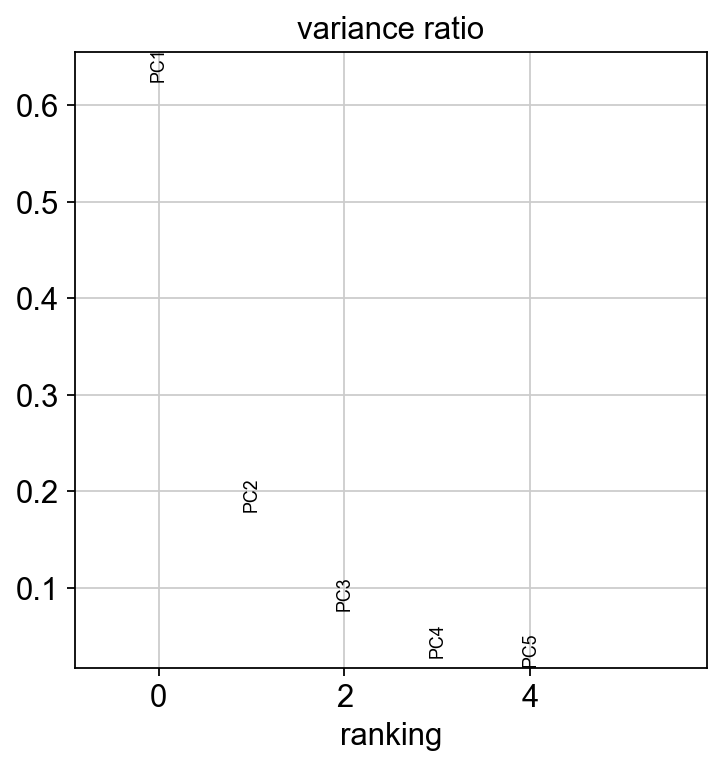

In [134]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata_bulk, n_pcs=5, log=False)

<Axes: title={'center': 'group'}, xlabel='PC1 (62.41999816894531%)', ylabel='PC2 (17.959999084472656%)'>

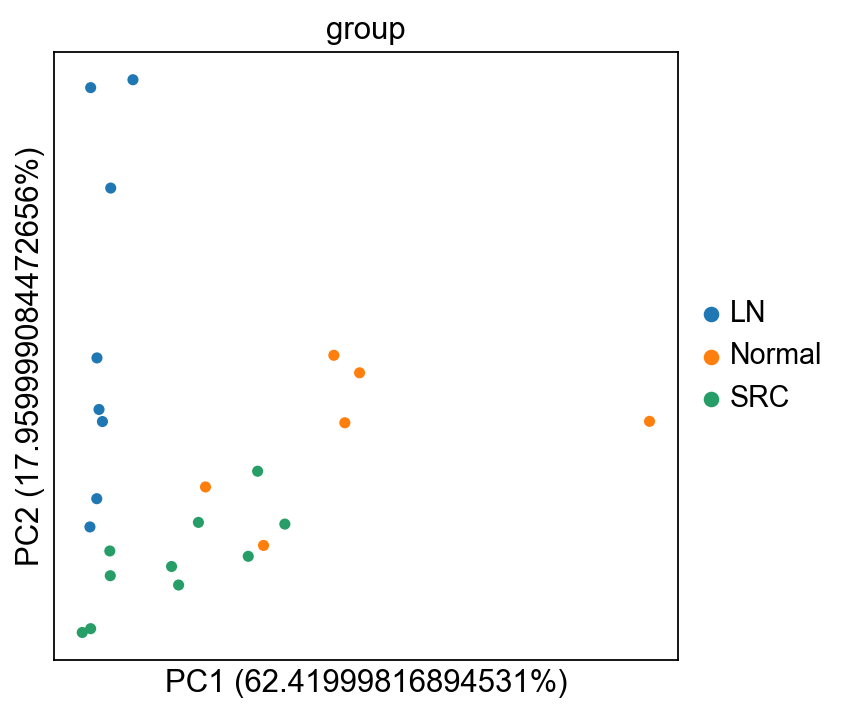

In [135]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata_bulk, 
          color='group',
          size=100,
          annotate_var_explained=True, 
          show=False)

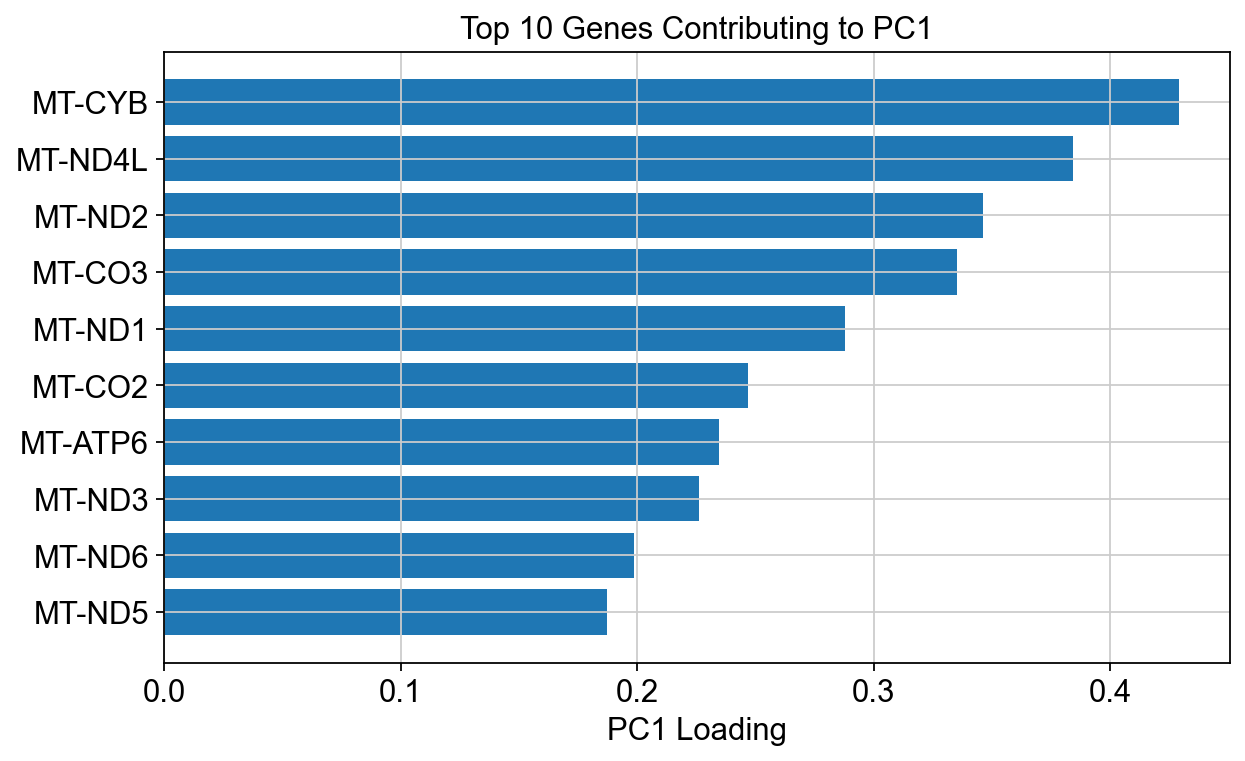

In [136]:
# Get top 10 genes for PC1
pc1 = adata_bulk.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata_bulk.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

In [137]:
# remove MT- genes from adata
adata_bulk = adata_bulk[:, ~adata_bulk.var_names.str.startswith('MT-')].copy()

In [138]:
adata_bulk.X = adata_bulk.layers['counts'].copy()
sc.pp.normalize_total(adata_bulk, target_sum=1e6)
sc.tl.pca(adata_bulk, n_comps=5)

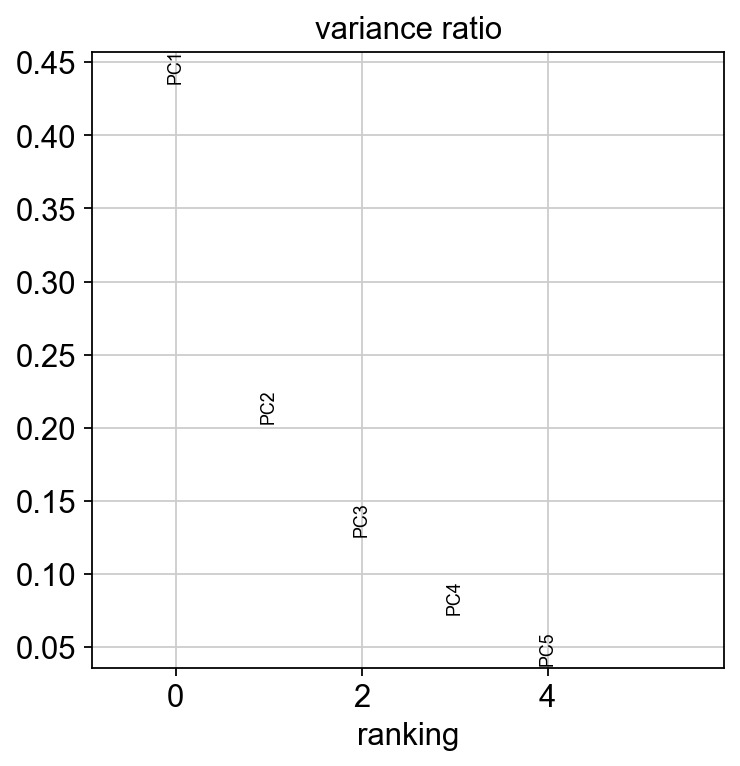

In [139]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca_variance_ratio(adata_bulk, n_pcs=5, log=False)

[<Axes: title={'center': 'group'}, xlabel='PC1 (43.540000915527344%)', ylabel='PC2 (20.31999969482422%)'>,
 <Axes: title={'center': 'annotation'}, xlabel='PC1 (43.540000915527344%)', ylabel='PC2 (20.31999969482422%)'>]

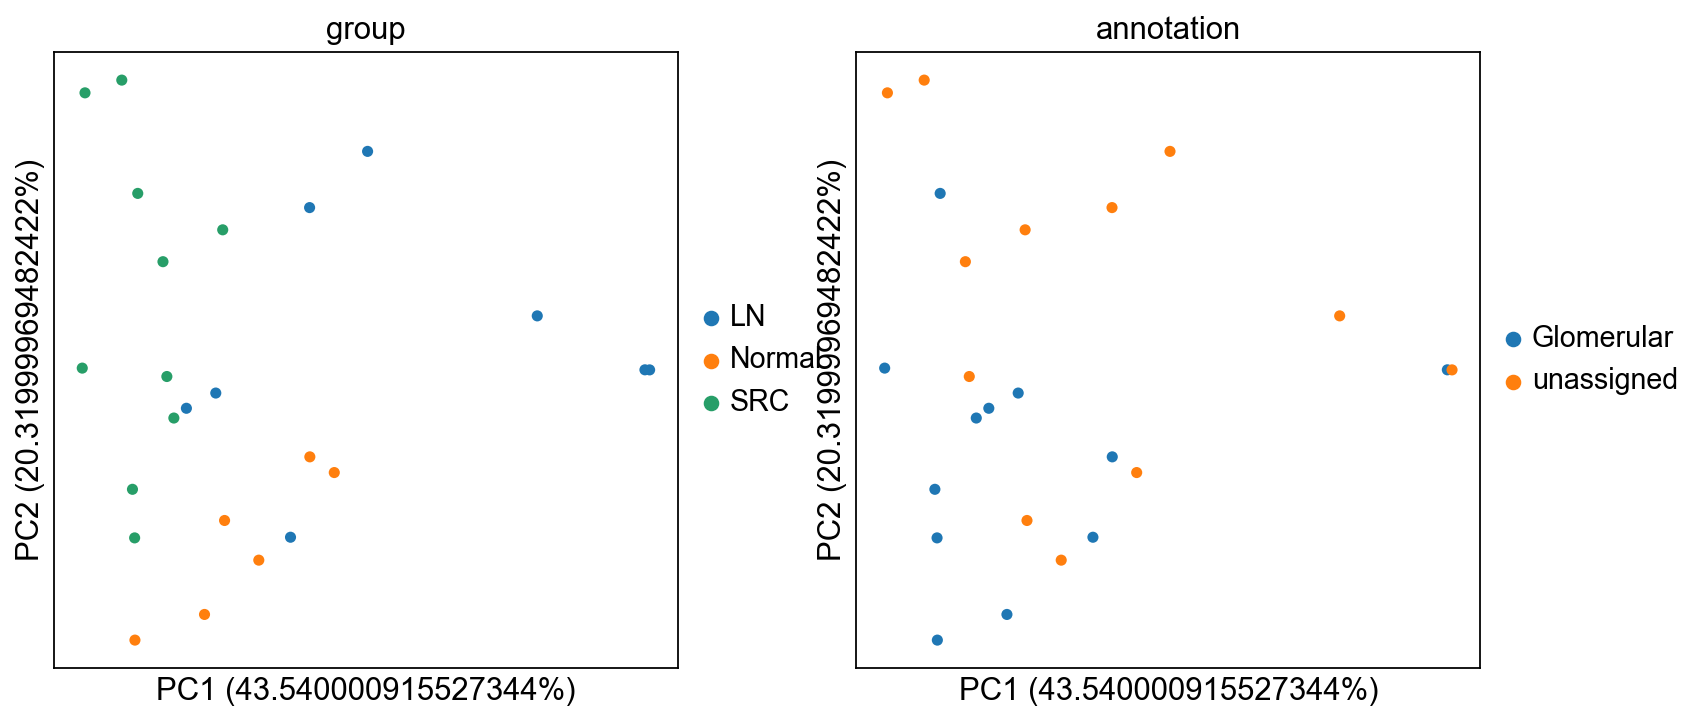

In [140]:
sc.set_figure_params(figsize=(5, 5))

sc.pl.pca(adata_bulk, 
          color=['group', 'annotation'],
          size=100,
          annotate_var_explained=True, 
          show=False)

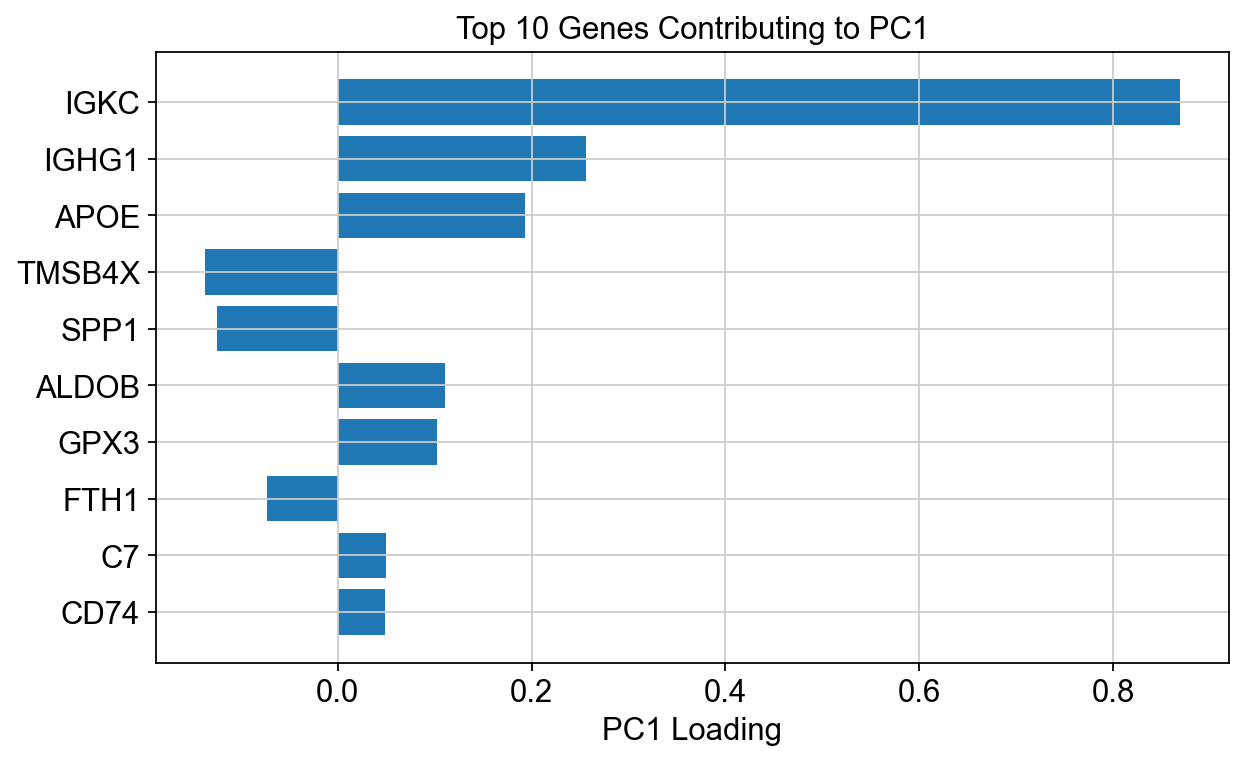

In [141]:
# Get top 10 genes for PC1
pc1 = adata_bulk.varm["PCs"][:, 0]
top_indices = np.argsort(np.abs(pc1))[::-1][:10]
top_genes = adata_bulk.var_names[top_indices]
top_values = pc1[top_indices]

# Plot
plt.figure(figsize=(8, 5))
plt.barh(top_genes[::-1], top_values[::-1])
plt.xlabel("PC1 Loading")
plt.title("Top 10 Genes Contributing to PC1")
plt.tight_layout()
plt.grid(True)
plt.show()

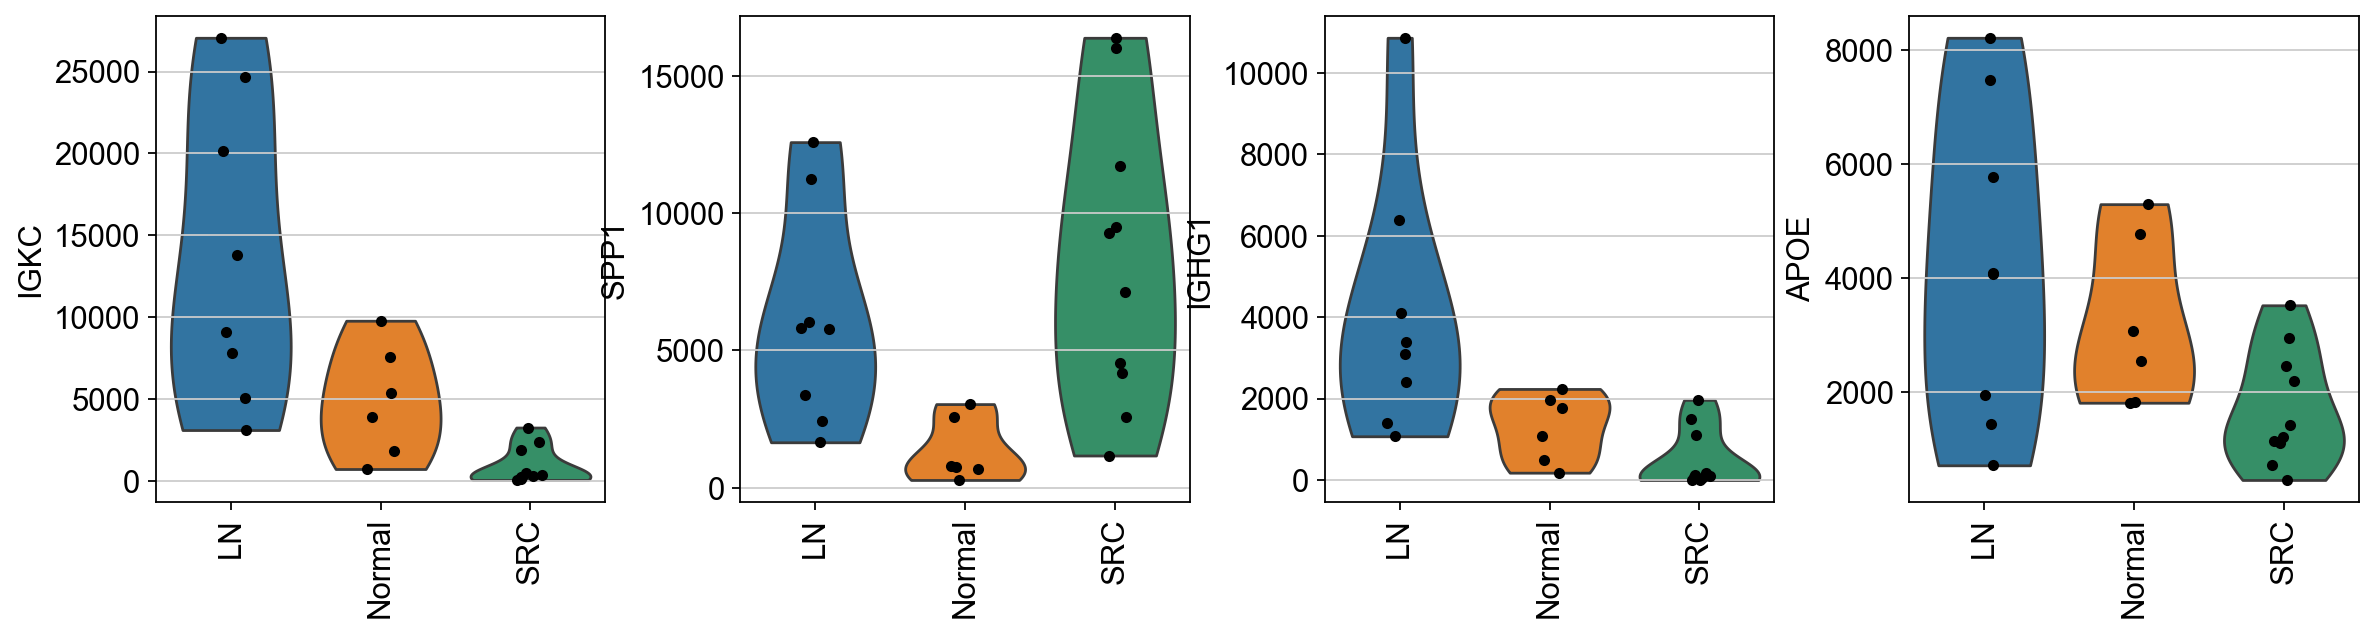

In [142]:
sc.set_figure_params(figsize=(4, 4))

sc.pl.violin(adata_bulk, keys=["IGKC", "SPP1", "IGHG1", "APOE"], 
             use_raw=False, groupby="group", size=5, rotation=90, multi_panel=True)

In [143]:
adata_bulk1 = adata_bulk[adata_bulk.obs["annotation"] == "Glomerular", :].copy()
adata_bulk2 = adata_bulk[adata_bulk.obs["annotation"] == "unassigned", :].copy()

In [144]:
# perform DE analysis using DESeq2
df_counts = adata_bulk1.to_df(layer="counts")
df_meta = adata_bulk1.obs.copy()
df_meta = df_meta[["group", "annotation"]]

df_counts.to_csv(f"{out_dir}/Glomerular_counts_bulk.csv")
df_meta.to_csv(f"{out_dir}/Glomerular_meta_bulk.csv")

In [145]:
df_counts = adata_bulk2.to_df(layer="counts")
df_meta = adata_bulk2.obs.copy()
df_meta = df_meta[["group", "annotation"]]

df_counts.to_csv(f"{out_dir}/Unassigned_counts_bulk.csv")
df_meta.to_csv(f"{out_dir}/Unassigned_meta_bulk.csv")

In [146]:
adata_bulk.write_h5ad(f"{out_dir}/adata_bulk.h5ad")